# De revisar las imágenes a elegir un primer modelo

Queremos reconocer condiciones de riesgo en cintas transportadoras de mineral. En esta primera etapa había que entender los datos disponibles, decidir qué podíamos aprender de ellos y comprobar si un modelo conseguía distinguir situaciones normales de otras que nos interesan como riesgo.

El trabajo terminó con un primer clasificador y una evaluación reservada. En el camino encontramos imágenes repetidas, etiquetas contradictorias, diferencias importantes entre datasets y señales que una red podría aprovechar sin reconocer realmente el objeto.

Este notebook reúne esos hallazgos y explica las decisiones con sus límites. Los resultados son los mismos de [la versión completa](entrega_modelado.ipynb); aquí priorizamos entender el proceso. Las imágenes y tablas están incorporadas y pueden leerse sin ejecutar código.

## 1. Primero, qué estamos prediciendo

Entrenamos **un clasificador de imágenes con tres clases**. Recibe una foto completa y asigna la categoría que considera más probable:

| Etiqueta del dataset | Qué significa en este trabajo |
|---|---|
| Normal Coal Flow | Flujo normal de mineral |
| Oversized Coal | Bloque grande, según las etiquetas de origen |
| Rock Bolts | Perno |

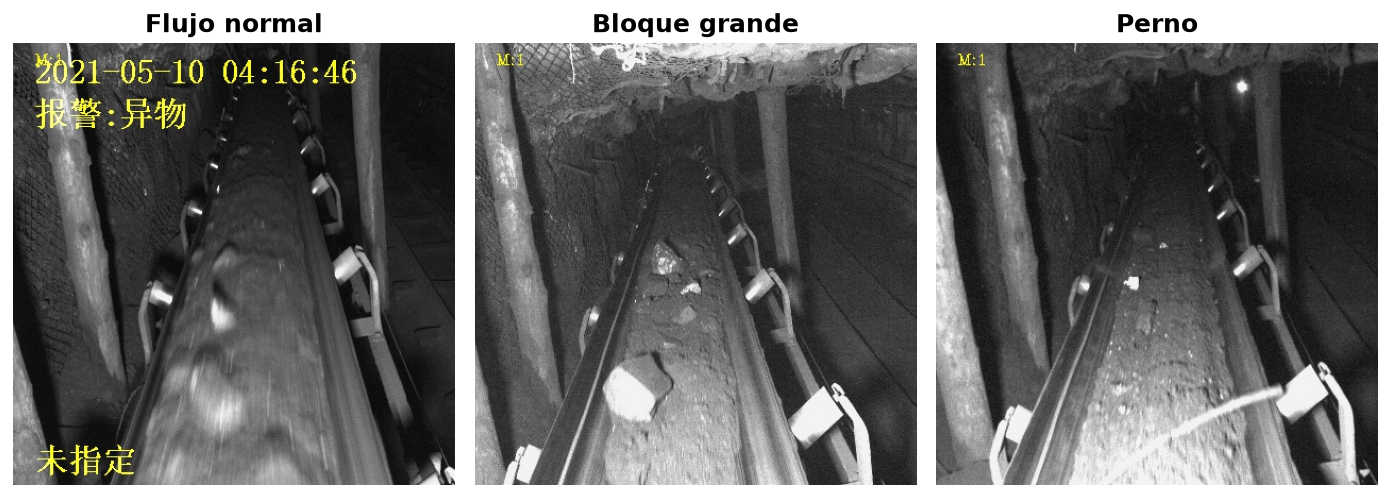

**Normal no significa «nada» ni necesariamente cinta vacía.** El mineral normal también contiene rocas; por eso no usamos «roca» como sinónimo de riesgo. Tampoco estamos midiendo el tamaño físico de un bloque en centímetros: aprendemos la distinción que trae el dataset.

A partir de las probabilidades de esas tres clases calculamos una **alerta normal/riesgo**, reuniendo bloque grande y perno como condiciones de riesgo. Es una segunda lectura de la misma red, no otro modelo entrenado. Más adelante veremos por qué acertar la etiqueta y activar la alerta no son exactamente la misma tarea.

| Tarea de computer vision | Qué entrega | En esta etapa |
|---|---|---|
| Clasificación | Una etiqueta para la imagen completa | Es lo que hicimos |
| Detección de objetos | Clase y rectángulo que ubica cada objeto | Requiere anotaciones adicionales |
| Segmentación | Qué píxeles pertenecen al objeto | No se implementó |

Para esta clasificación usamos etiquetas por foto. No fue necesario dibujar bounding boxes. El modelo tampoco cuenta objetos ni resuelve explícitamente una foto con varias categorías a la vez.

## 2. Los dos datasets no estaban listos para la misma tarea

| | Coal: carbón | Iron: hierro |
|---|---|---|
| Imágenes disponibles | 4.800 | 19.211 |
| Tamaño | 416 × 416 | 1.280 × 720 |
| Organización | Train/test y tres carpetas de clase | Doce carpetas de secuencias |
| Etiquetas disponibles localmente | Clase por imagen, dada por su carpeta | Sin etiqueta verificada por fotograma |

En **coal** encontramos un punto de partida para clasificación, aunque sus etiquetas y particiones necesitaban revisión. Las clases originales estaban perfectamente equilibradas: 1.600 imágenes de cada una. Ese balance es una propiedad de la colección, no una estimación de cuántos incidentes ocurren en una planta.

En **iron**, tener más archivos no significaba tener más ejemplos independientes y etiquetados. Los nombres permiten ordenar imágenes por un índice numérico, y las muestras muestran momentos parecidos de una misma secuencia. No conocemos su equivalencia en segundos ni podemos reconstruir todos los eventos con certeza.

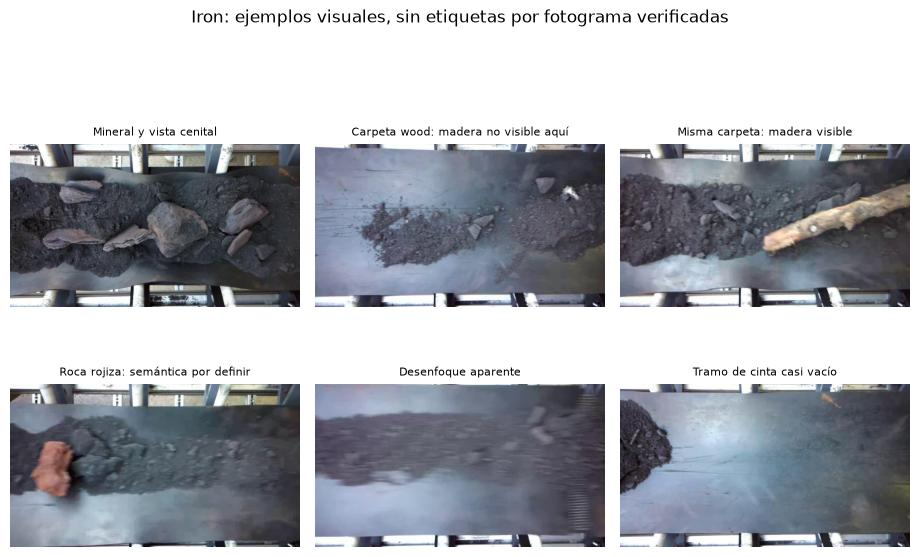

Un hallazgo importante fue que las carpetas llamadas `wood` también contienen imágenes donde no se ve madera. Por lo tanto, convertir el nombre de la carpeta en etiqueta para todos sus fotogramas introduciría errores. **Decidimos modelar primero con coal y mantener iron como una siguiente etapa de anotación y transferencia.**

## 3. Qué vimos al explorar las imágenes

Las imágenes de coal presentan iluminación desigual, zonas oscuras, desenfoque y pernos que pueden ocupar muy pocos píxeles. También aparecen encuadres distintos y texto amarillo con fechas o mensajes. Iron tiene otra perspectiva, más color y tramos de cinta casi vacía. Estas diferencias importan porque una red también puede aprender el fondo o la cámara.

Medimos brillo, contraste y una aproximación de nitidez. Revisamos automáticamente las 4.800 imágenes de coal y una muestra temporal de 288 de iron, además de mirar galerías seleccionadas. No inspeccionamos manualmente cada archivo.

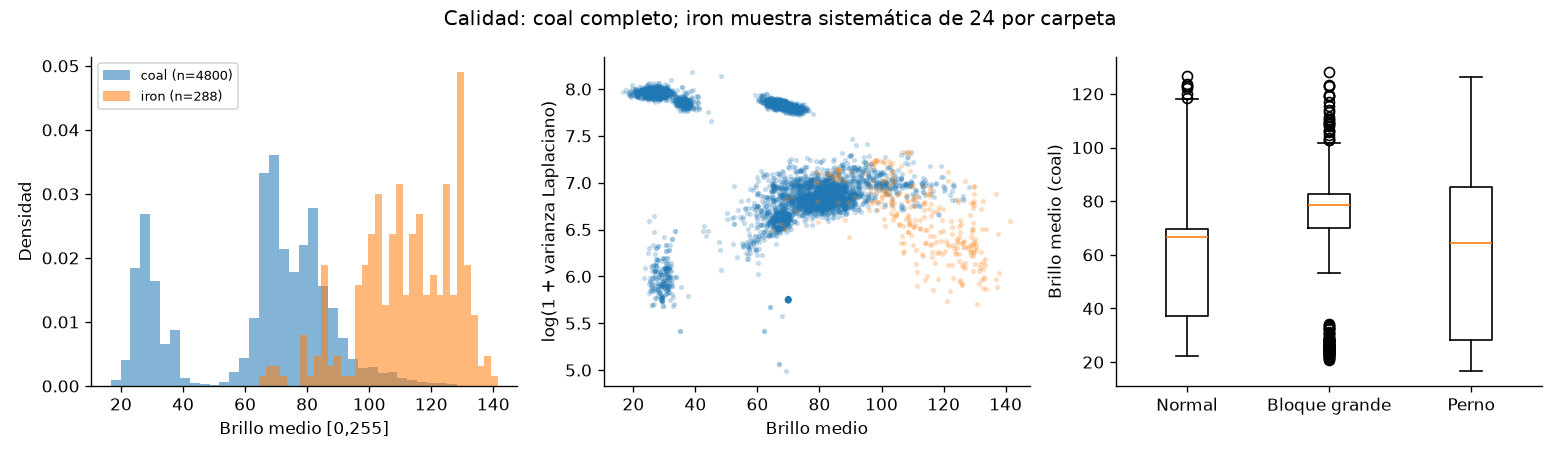

En la muestra, iron es generalmente más claro que coal. Dentro de coal también cambia la distribución de brillo según la clase. La medida de nitidez debe interpretarse con cuidado: responde tanto al enfoque como a la textura del mineral y al texto. No la usamos como una regla automática para decidir qué imagen era buena o mala.

Una señal adicional apareció al modelar: un clasificador que solo usaba medidas simples de calidad y un indicador visual de texto llegó a macro-F1 **0,768** en validación. Eso muestra que parte de las clases se puede separar con señales generales. No demuestra cuánto corresponde a objetos reales y cuánto a condiciones de captura; fue una razón para investigar los posibles atajos.

## 4. Qué retiramos y por qué

Encontramos imágenes exactamente iguales guardadas con etiquetas distintas. Conservarlas habría pedido al modelo aprender respuestas incompatibles. La decisión fue excluir provisionalmente todos los archivos de esos grupos, en lugar de elegir una etiqueta por mayoría o por conveniencia.

| Paso sobre coal | Archivos | Motivo |
|---|---:|---|
| Colección original | 4.800 | Punto de partida |
| Excluir 65 contenidos con etiquetas contradictorias | −135 | La misma imagen tenía clases diferentes |
| Conservar una sola copia de cada contenido consistente | −165 | Evitar contar repetidamente la misma observación |
| **Candidatos conservados** | **4.500** | Imágenes únicas para preparar el experimento |

También había una imagen idéntica entre el entrenamiento y el test originales, con etiquetas diferentes. Eso hacía necesario revisar la evaluación antes de usar sus resultados como evidencia.

Los originales quedaron intactos y las exclusiones se registraron por archivo. No eliminamos automáticamente fotos oscuras o borrosas: son dificultades que el proyecto necesita aprender a manejar. Tampoco corregimos una etiqueta solo porque el modelo la predijera de otra manera.

Esta limpieza resuelve problemas comprobados, pero **no certifica que las 4.500 etiquetas restantes sean correctas**. Algunas imágenes siguen siendo dudosas y necesitan revisión con criterios más claros.

## 5. Cómo intentamos que la evaluación fuera más honesta

Si dos fotos casi iguales quedan en entrenamiento y prueba, el resultado puede parecer mejor de lo que será frente a una situación nueva. Por eso agrupamos imágenes similares y usamos la hora presente en los nombres como otra señal de cercanía.

Al comienzo, los métodos de similitud de imagen confundían fondos estáticos con fotos del mismo contenido. Añadimos una comparación de píxeles en la zona de la cinta antes de aceptar esos pares. Las imágenes cercanas se mantuvieron en el mismo grupo; no se descartaron todas.

| Partición | Imágenes | Uso |
|---|---:|---|
| Entrenamiento | 3.211 | Aprender los parámetros |
| Validación | 644 | Elegir ajustes, modelo y umbral de alerta |
| Prueba final | 645 | Evaluar lo ya elegido |

La separación quedó fijada antes de entrenar y no hay imágenes idénticas ni grupos definidos compartidos entre particiones. Esta es una **nueva referencia de evaluación**, por lo que no se compara directamente con resultados obtenidos usando el test original.

Hay un límite importante: faltan fechas y videos originales para identificar eventos con certeza. Las ventanas horarias de cinco minutos y la similitud son aproximaciones. Pueden unir tomas diferentes o dejar relaciones sin detectar. Reducimos una fuente de contaminación; no demostramos independencia completa entre eventos.

## 6. El texto sobreimpreso merecía su propio experimento

Las fechas y los mensajes de alarma podían facilitar la clasificación sin que la red reconociera el objeto. Un indicador de píxeles amarillos, compatible con texto, apareció aproximadamente en 90% de las imágenes normales de desarrollo, 86% de las de pernos y 21% de las de bloques. Es una asociación visual, no una lectura del contenido del mensaje.

Probamos ocultar zonas fijas donde aparecían esos textos. Aplicamos la misma regla a todas las clases, incluso cuando no había texto, para no crear una marca que dependiera de la etiqueta.

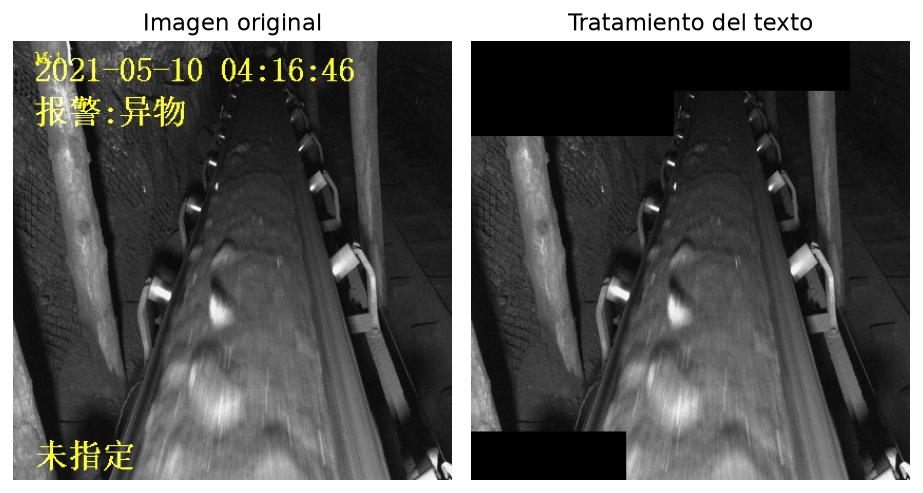

En una primera comparación, manteniendo fija la parte de la red que extrae características, ocultar esas zonas bajó el macro-F1 de validación de **0,904 a 0,889**. Esa diferencia no prueba que el modelo estuviera leyendo el texto: los rectángulos también ocultan parte de la escena y podrían tapar extremos de objetos. La comparación mide el efecto del tratamiento completo.

Mantuvimos esta variante como una línea de trabajo y probamos adaptarla mejor al dominio. El modelo finalmente seleccionado utiliza ese tratamiento. **Los rectángulos negros son preprocesamiento: no son cajas predichas ni una segmentación.** En las galerías se ve la fuente enmascarada; la red recibe además el cambio de tamaño y la normalización.

## 7. Cómo pasamos de una referencia al modelo elegido

Elegimos ResNet-18 preentrenada para reutilizar características visuales que ya había aprendido con otras imágenes. Eso no significa que ya reconociera nuestros pernos. Primero entrenamos una salida nueva para las tres clases y después permitimos que su último bloque se ajustara a estas cintas. A esto último se le llama *fine-tuning*.

Mantuvimos la misma separación de datos en las comparaciones. El macro-F1 resume precisión y capacidad de recuperar casos de cada clase, dando igual peso a las tres. Va de 0 a 1 y no equivale al porcentaje total de aciertos.

| Experimento | Macro-F1 de validación | Qué aportó |
|---|---:|---|
| Referencia que no mira la imagen | 0.167 | Fijar un punto de comparación |
| Medidas simples de calidad | 0.768 | Identificar señales generales y posibles atajos |
| ResNet-18 con salida nueva, imágenes originales | 0.904 | Reutilizar características visuales |
| Misma estrategia, zonas de texto ocultadas | 0.889 | Examinar el efecto de quitar esas zonas |
| **Texto ocultado y ajuste del último bloque** | 0.921 | Mejor resultado de validación |
| Agregar variaciones de brillo y contraste | 0.917 | No superó al ajuste sin esas variaciones |
| Extractor congelado con tamaño 320 | 0.901 | Mejoró frente a 224 congelado, sin superar al elegido |

La mejor opción fue **ResNet-18 con texto ocultado, imágenes de 224 × 224 y ajuste del último bloque**. Conservamos la tercera época de ese ajuste —la tercera pasada por los datos de entrenamiento— porque fue la mejor en validación.

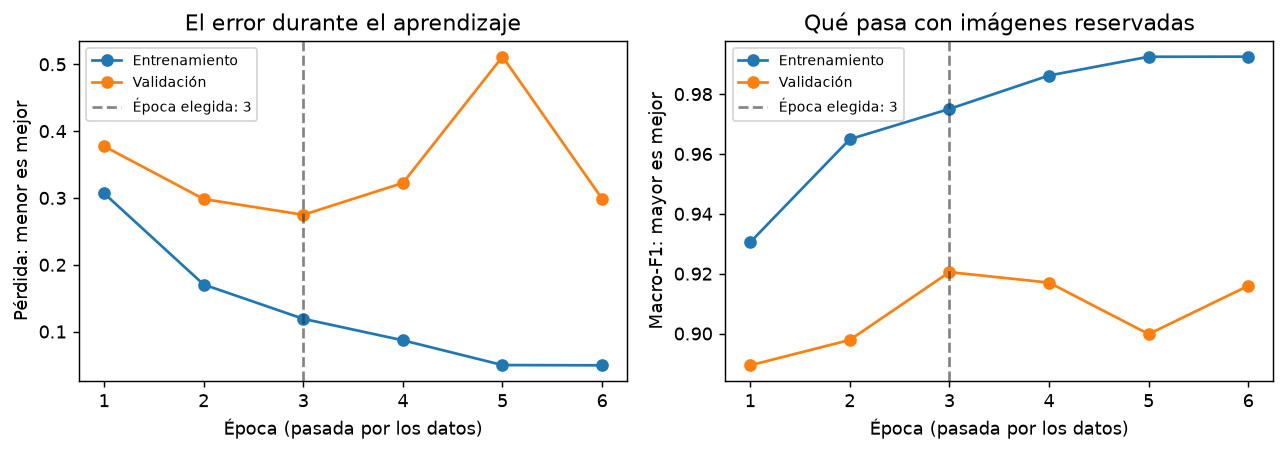

En las épocas siguientes el modelo seguía mejorando con los datos usados para aprender, pero no mejoraba de manera sostenida con las imágenes reservadas. Esa brecha es una señal de sobreajuste. Conservar el último entrenamiento habría sido una decisión peor que guardar la mejor época.

Las variaciones de iluminación no aportaron una mejora observada en esta corrida. La mayor resolución ayudó al extractor fijo, pero no superó al modelo ajustado. Son resultados útiles para decidir dónde seguir trabajando; con una sola semilla por configuración, las diferencias pequeñas todavía requieren confirmación.

## 8. Qué nos dicen los resultados finales

El modelo y la regla de alerta se eligieron con validación. Después se evaluaron sobre las 645 imágenes de prueba, sin volver a ajustar a partir de ese resultado.

**Para las tres etiquetas**, hubo **601 aciertos de 645 imágenes: 93.2%**. El macro-F1 fue **0.932**.

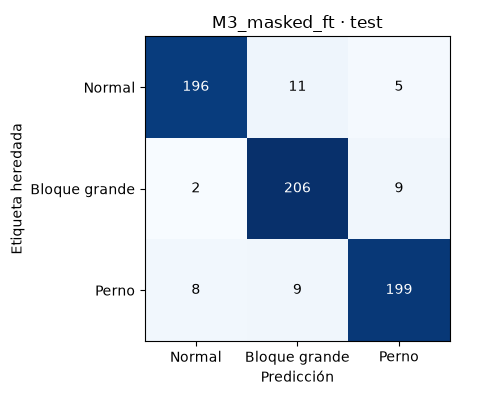

Las filas representan la etiqueta de la carpeta y las columnas la predicción. Los aciertos están en la diagonal: 196 imágenes normales, 206 bloques y 199 pernos. Los demás casos son confusiones entre categorías, no necesariamente riesgos que pasaron sin alerta.

**Para normal/riesgo**, sumamos las probabilidades de bloque y perno y las comparamos con un umbral elegido en validación para dar más importancia a no omitir riesgos. No entrenamos una segunda red.

| Resultado de la alerta, según las etiquetas disponibles | Prueba final |
|---|---:|
| Riesgos que activaron alerta | **432 de 433 · 99.8%** |
| Riesgos omitidos | **1** |
| Imágenes normales que activaron falsa alarma | **24 de 212 · 11.3%** |

Si un bloque se confunde con un perno, la etiqueta está equivocada pero la alerta todavía puede ser útil. También puede haber alerta cuando «normal» es la clase individual más probable: la regla usa las probabilidades combinadas y un umbral conservador, no solo el nombre de la clase elegida.

La sensibilidad es alta en esta prueba, pero las falsas alarmas siguen siendo importantes. Además, cerca de dos tercios de este test son imágenes de riesgo, por el balance de las clases. No conocemos esa frecuencia en una planta; por eso no trasladamos directamente la precisión de estas alarmas a una operación real.

## 9. Mirar los errores cambió la interpretación de las métricas

Los errores muestran pernos finos sobre material oscuro, cambios de encuadre y algunas etiquetas que no resultan fáciles de conciliar con lo visible. Esto nos obliga a distinguir un fallo del modelo de un posible problema en la referencia con la que lo evaluamos. La predicción por sí sola no resuelve esa duda.

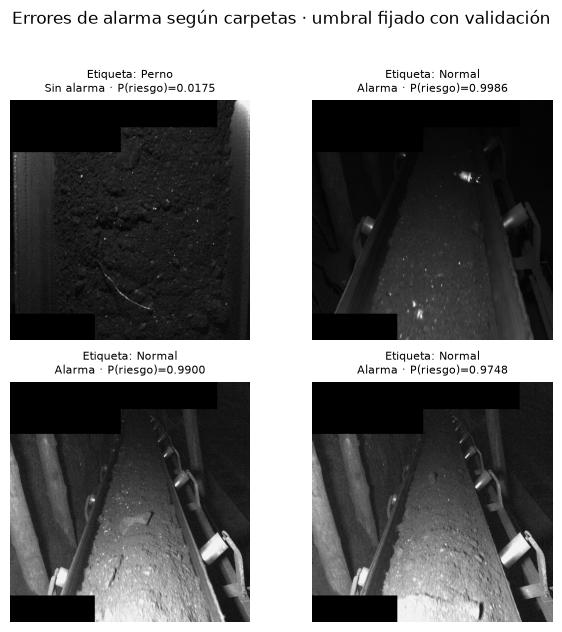

La única omisión de riesgo al umbral fijado corresponde a una imagen etiquetada como perno, con una línea delgada y curva sobre mineral oscuro. Las otras tres imágenes son ejemplos dirigidos de falsas alarmas según las carpetas, no una muestra representativa de su frecuencia.

Esta revisión se hizo para entender las dificultades. No cambiamos etiquetas, modelo ni umbral usando el resultado de prueba. Los casos dudosos quedan como insumo para una revisión posterior, con reglas de anotación y, de ser posible, una segunda persona que permita resolver desacuerdos.

## 10. Los supuestos que sostienen este primer experimento

Trabajamos con las etiquetas de carpeta como referencia después de excluir contradicciones exactas. Es una base útil para comenzar, pero todavía suponemos que la mayor parte de esas etiquetas describe la condición que queremos aprender. La limpieza automática no reemplaza una revisión semántica.

También usamos una sola clase por imagen. Si una foto contiene un bloque y un perno, el modelo igualmente devuelve una categoría principal; aún falta establecer cómo queremos representar esos casos. En la salida de alarma asumimos que ambas categorías se pueden reunir como riesgo, aunque sus causas y costos operacionales puedan ser distintos.

Finalmente, tratamos los grupos visuales y horarios como una aproximación a eventos relacionados. Lo comprobado es que los grupos definidos no cruzan particiones. No está comprobado que representen todos los eventos reales ni que cada grupo corresponda a una toma independiente.

Estos supuestos delimitan lo que estamos evaluando: **clasificar las categorías existentes en nuevas imágenes reservadas de esta colección**. No estamos probando reconocimiento de cualquier objeto extraño ni capacidad de medir sobretamaño físico.

## 11. Qué sigue siendo una limitación

La evaluación es interna y usa un número limitado de grupos. No hemos demostrado que el modelo conserve su desempeño en otra cámara, mineral o planta. Tampoco podemos convertir una tasa por imagen en alarmas por hora sin video, frecuencia de captura y una regla temporal para reunir alertas repetidas.

Se ejecutó una semilla por configuración. El resultado elegido es el mejor observado en estas pruebas, no una garantía de que cada diferencia se repetirá en nuevos entrenamientos. Además, revisar varias opciones con la misma validación también puede favorecer decisiones específicas de esa muestra.

Los rectángulos usados para ocultar texto eliminan algo de escena y podrían afectar objetos que pasen por esas zonas. Las clases tampoco definen por sí solas un criterio operacional de tamaño o gravedad. Por estas razones, el resultado es un **primer modelo con evidencia y problemas identificados**, que todavía necesita validación adicional para orientar decisiones en planta.

Aun con esos límites, ya sabemos qué dificultades concretas merece la pena investigar: calidad de etiquetas, objetos delgados, cambios de vista, falsas alarmas y separación de eventos. Esa información es más útil para el siguiente paso que seguir cambiando de arquitectura sin una pregunta clara.

## 12. Próximos pasos, en un orden que podamos justificar

1. **Revisar las etiquetas y los casos ambiguos.** Acordar qué cuenta como bloque grande, cómo tratar objetos simultáneos y qué hacer cuando el objeto casi no se ve. La revisión debe incluir ejemplos que el modelo acierta, no solo sus errores, para no adaptar la verdad de referencia a sus predicciones.

2. **Reforzar la evaluación de coal.** Recuperar videos o fechas si existen, revisar la separación por eventos y repetir configuraciones con otras semillas. También necesitamos conocer el costo de una falsa alarma frente a una omisión antes de fijar un umbral operacional.

3. **Anotar una muestra temporal de iron.** Hay 288 candidatos preparados, todos sin revisar ni etiquetar. Deberían cubrir presencia y ausencia real de objetos, cinta vacía y transiciones. Solo después podremos comparar modelos por separado y uno entrenado con ambos orígenes, midiendo el resultado en cada dominio. Más archivos no bastan para justificar la mezcla.

4. **Elegir la siguiente tarea según el uso esperado.** Si necesitamos ubicar el objeto, preparar un piloto con cajas para detección; si necesitamos su contorno, evaluar segmentación. Los datos sintéticos pueden investigarse para cubrir una carencia concreta, con objetos y fondos de entrenamiento y evaluación sobre imágenes reales. No reemplazan las etiquetas ni la validación en el entorno destino.

Por ahora tenemos un flujo reproducible que va desde la revisión de los datos hasta un modelo seleccionado y una prueba reservada. La conclusión de esta etapa es que la clasificación permite empezar a estudiar el problema, y que mejorar la definición y la calidad de los datos es una parte central del trabajo que viene.

## Referencia y comprobación opcional

El detalle de las ejecuciones está en [entrega_modelado.ipynb](entrega_modelado.ipynb) y las instrucciones en [README.md](README.md). Esta v2 reorganiza la explicación; no entrena otro modelo ni modifica los resultados.

La regla de alerta usa probabilidad de bloque + probabilidad de perno ≥ **0.019967**. El umbral se eligió maximizando F2 en validación, que pondera más la sensibilidad. No representa todavía una función de costos acordada con una planta.

La única celda de código, oculta al final, comprueba las cifras a partir de los artefactos locales. No es necesaria para leer el notebook.

In [1]:
from pathlib import Path
import csv, hashlib, json

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/results/patrick_v1/final_test.json').exists())
results = root / 'data/results/patrick_v1'
final = json.loads((results / 'final_test.json').read_text())
with (results / 'runs' / final['selection']['run'] / 'test_predictions.csv').open() as f:
    rows = list(csv.DictReader(f))
correct = sum(int(r['target']) == int(r['prediction']) for r in rows)
threshold = final['selection']['risk_threshold']
tp = sum(int(r['target']) != 0 and float(r['p1']) + float(r['p2']) >= threshold for r in rows)
fp = sum(int(r['target']) == 0 and float(r['p1']) + float(r['p2']) >= threshold for r in rows)
assert len(rows) == 645 and correct == 601
assert tp == final['test']['risk']['tp'] == 432
assert fp == final['test']['risk']['fp'] == 24
checkpoint = root / 'data/weights/patrick_v1' / (final['selection']['run'] + '.pt')
assert hashlib.sha256(checkpoint.read_bytes()).hexdigest() == final['selection']['weights_sha256']
print('Cifras comprobadas: 601/645 etiquetas correctas; 432/433 riesgos con alerta; 24/212 falsas alarmas.')
print('Se conservan el modelo y la prueba de la v1.')

Cifras comprobadas: 601/645 etiquetas correctas; 432/433 riesgos con alerta; 24/212 falsas alarmas.
Se conservan el modelo y la prueba de la v1.
